# Phase 1: Space Weather Data Acquisition & Exploratory Data Analysis (EDA)
**Project:** HelioShield — Solar Storm & Satellite Disruption Forecaster  
**Objective:** Load historical geomagnetic storm data ($K_p$ Index, Sunspot Number, $F_{10.7}$ Solar Flux) from GFZ Potsdam, inspect data quality, and visualize Solar Cycle 25 storm trends.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("dark_background")

# Official NASA Goddard Space Physics Data Facility (SPDF) Hourly OMNI2 Archive
base_url = "https://spdf.gsfc.nasa.gov/pub/data/omni/low_res_omni/omni2_{}.dat"

# Key NASA OMNI2 column indices (0-based) from official NASA format specification:
# 0: Year, 1: Day of Year, 2: Hour, 14: IMF Bz GSM (nT), 23: Proton Density (n/cc),
# 24: Solar Wind Speed (km/s), 38: Kp*10 Index, 39: Sunspot Number, 40: Dst Index (nT), 50: F10.7 Flux
use_cols = [0, 1, 2, 14, 23, 24, 38, 39, 40, 50]
col_names = ["year", "doy", "hour", "bz_gsm", "proton_density", "wind_speed", "kp_10", "sunspot_num", "dst", "f10_7"]

dfs = []
for yr in range(2016, 2026):
    print(f"Fetching NASA OMNI2 data for {yr}...")
    df_yr = pd.read_csv(base_url.format(yr), sep=r"\s+", header=None, usecols=use_cols, names=col_names)
    dfs.append(df_yr)

df = pd.concat(dfs, ignore_index=True)

# Create proper datetime column from Year, Day-of-Year, and Hour
df["timestamp"] = pd.to_datetime(
    df["year"].astype(str) + "-" + df["doy"].astype(str).str.zfill(3),
    format="%Y-%j"
) + pd.to_timedelta(df["hour"], unit="h")

print(f"\nLoaded {len(df):,} hourly NASA spacecraft records!")
df.head(10)

Fetching NASA OMNI2 data for 2016...
Fetching NASA OMNI2 data for 2017...
Fetching NASA OMNI2 data for 2018...
Fetching NASA OMNI2 data for 2019...
Fetching NASA OMNI2 data for 2020...
Fetching NASA OMNI2 data for 2021...
Fetching NASA OMNI2 data for 2022...
Fetching NASA OMNI2 data for 2023...
Fetching NASA OMNI2 data for 2024...
Fetching NASA OMNI2 data for 2025...

Loaded 87,672 hourly NASA spacecraft records!


,year,doy,hour,bz_gsm,proton_density,wind_speed,kp_10,sunspot_num,dst,f10_7,timestamp
0,2016,1,0,-14.1,2.0,463.0,60,37,-116,95.1,2016-01-01 00:00:00
1,2016,1,1,-13.2,0.8,451.0,60,37,-114,95.1,2016-01-01 01:00:00
2,2016,1,2,-13.0,1.1,450.0,60,37,-102,95.1,2016-01-01 02:00:00
3,2016,1,3,-13.1,1.7,434.0,53,37,-98,95.1,2016-01-01 03:00:00
4,2016,1,4,-12.7,0.9,430.0,53,37,-96,95.1,2016-01-01 04:00:00
5,2016,1,5,-11.0,1.7,436.0,53,37,-94,95.1,2016-01-01 05:00:00
6,2016,1,6,-3.4,2.6,444.0,50,37,-92,95.1,2016-01-01 06:00:00
7,2016,1,7,-8.9,1.4,436.0,50,37,-83,95.1,2016-01-01 07:00:00
8,2016,1,8,-7.9,1.8,430.0,50,37,-80,95.1,2016-01-01 08:00:00
9,2016,1,9,-3.2,1.0,452.0,33,37,-75,95.1,2016-01-01 09:00:00


### Step 2: Data Cleaning & Handling NASA Spacecraft Sentinel Values
NASA's OMNI2 specification encodes missing sensor readings using sentinel numbers (`999.9` for $B_z$ and proton density, `9999.0` for wind speed, `99` for $K_p \times 10$, `999` for sunspot number, and `999.9` for $F_{10.7}$). Below, we replace these with `NaN`, scale `kp_10` to the standard `0–9` $K_p$ index, and inspect missing value percentages and storm severity distribution.

In [2]:
# Replace NASA OMNI2 official sentinel missing-value codes with NaN
sentinel_map = {
    "bz_gsm": 999.9,
    "proton_density": 999.9,
    "wind_speed": 9999.0,
    "kp_10": 99,
    "sunspot_num": 999,
    "dst": 99999,
    "f10_7": 999.9
}

for col, sentinel in sentinel_map.items():
    df[col] = df[col].replace(sentinel, np.nan)

# Convert kp_10 (e.g., 60) to actual Kp Index (e.g., 6.0)
df["kp"] = df["kp_10"] / 10.0

# Create a human-readable NOAA Geomagnetic Storm Category label (G0 to G5)
def categorize_storm(kp):
    if pd.isna(kp):
        return np.nan
    elif kp < 5.0:
        return "G0 (Quiet/Unsettled)"
    elif kp < 6.0:
        return "G1 (Minor)"
    elif kp < 7.0:
        return "G2 (Moderate)"
    elif kp < 8.0:
        return "G3 (Strong)"
    elif kp < 9.0:
        return "G4 (Severe)"
    else:
        return "G5 (Extreme)"

df["storm_level"] = df["kp"].apply(categorize_storm)

print("--- Missing Values (%) per Column ---")
print((df.isna().mean() * 100).round(2))

print("\n--- Geomagnetic Storm Distribution (2016–2025) ---")
print(df["storm_level"].value_counts())

--- Missing Values (%) per Column ---
year              0.00
doy               0.00
hour              0.00
bz_gsm            0.40
proton_density    0.94
wind_speed        0.81
kp_10             0.00
sunspot_num       0.00
dst               0.00
f10_7             0.03
timestamp         0.00
kp                0.00
storm_level       0.00
dtype: float64

--- Geomagnetic Storm Distribution (2016–2025) ---
storm_level
G0 (Quiet/Unsettled)    85827
G1 (Minor)               1305
G2 (Moderate)             354
G3 (Strong)               123
G4 (Severe)                57
G5 (Extreme)                6
Name: count, dtype: int64


### Step 3: Time-Series Imputation & Exploratory Visualization
Because missing spacecraft readings (`< 1%`) occur during brief telemetry dropouts, we apply forward-fill (`ffill`) followed by backward-fill (`bfill`) along the hourly timeline. Next, we visualize the relationship between southward magnetic field ($B_z$), solar wind speed, and geomagnetic storm intensity ($K_p$).

Remaining missing values: 0


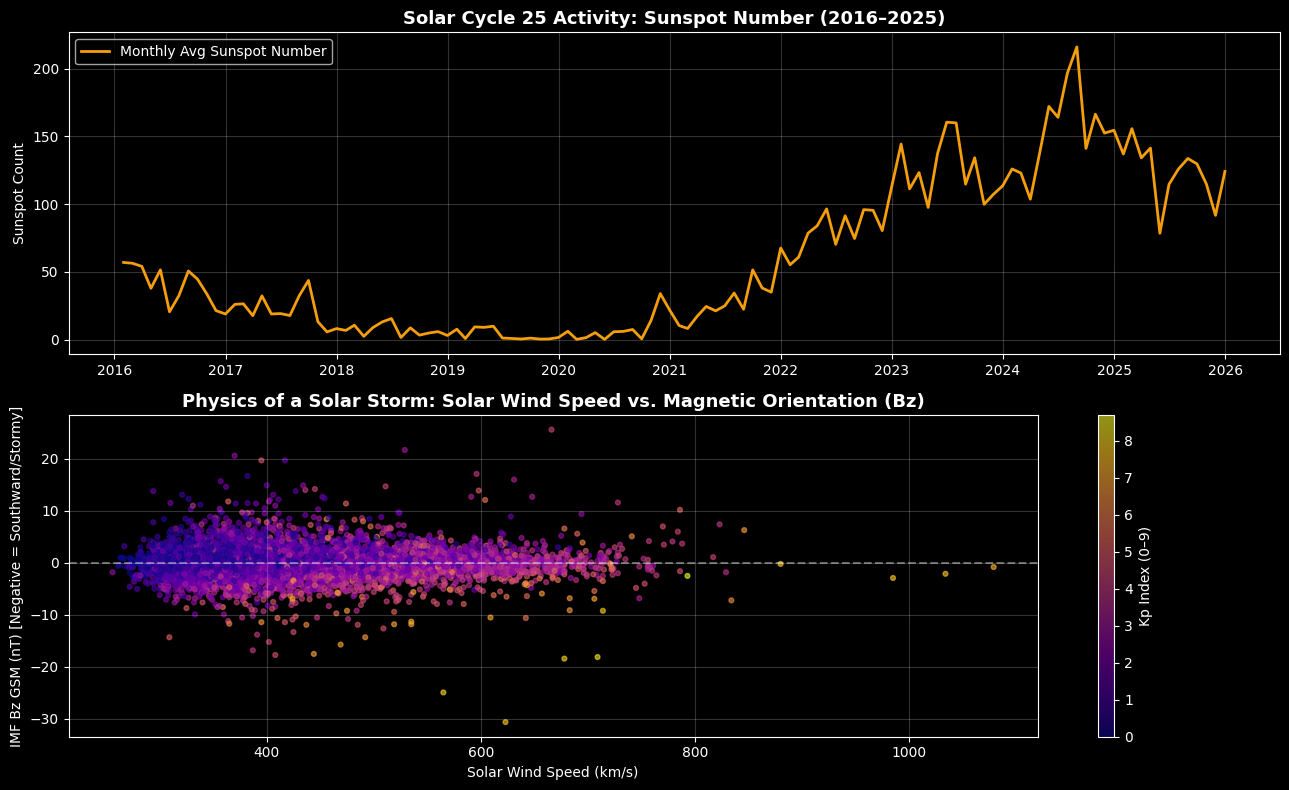

In [3]:
# Fill <1% telemetry dropouts using time-series forward/backward fill
sensor_cols = ["bz_gsm", "proton_density", "wind_speed", "f10_7"]
df[sensor_cols] = df[sensor_cols].ffill().bfill()

print("Remaining missing values:", df.isna().sum().sum())

# Plot 1: Monthly average Kp & Sunspot Number (Solar Cycle 25 rise)
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

monthly = df.set_index("timestamp").resample("ME").agg({"kp": "max", "sunspot_num": "mean", "wind_speed": "max"})

axes[0].plot(monthly.index, monthly["sunspot_num"], color="#f59e0b", linewidth=2, label="Monthly Avg Sunspot Number")
axes[0].set_title("Solar Cycle 25 Activity: Sunspot Number (2016–2025)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Sunspot Count")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Plot 2: Solar Wind Speed vs. Magnetic Field Bz colored by Kp Storm Score
sample = df.sample(n=8000, random_state=42)
sc = axes[1].scatter(sample["wind_speed"], sample["bz_gsm"], c=sample["kp"], cmap="plasma", alpha=0.6, s=12)
axes[1].axhline(0, color="white", linestyle="--", alpha=0.4)
axes[1].set_title("Physics of a Solar Storm: Solar Wind Speed vs. Magnetic Orientation (Bz)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Solar Wind Speed (km/s)")
axes[1].set_ylabel("IMF Bz GSM (nT) [Negative = Southward/Stormy]")
plt.colorbar(sc, ax=axes[1], label="Kp Index (0–9)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Step 4: Verify Live NOAA SWPC Satellite Telemetry Schema
Before moving to ML modeling, we fetch a live snapshot from NOAA's Space Weather Prediction Center (DSCOVR/IMAP L1 satellite feeds) to confirm that real-time `bz_gsm`, `wind_speed`, and `proton_density` units match our NASA OMNI2 training columns.

In [5]:
import requests

headers = {"User-Agent": "HelioShield-SpaceWeather/1.0"}

# Primary NOAA SWPC 1-day feeds + fallback to Real-Time Solar Wind (RTSW) 1-minute feeds
mag_urls = [
    "https://services.swpc.noaa.gov/products/solar-wind/mag-1-day.json",
    "https://services.swpc.noaa.gov/json/rtsw/rtsw_mag_1m.json"
]
plasma_urls = [
    "https://services.swpc.noaa.gov/products/solar-wind/plasma-1-day.json",
    "https://services.swpc.noaa.gov/json/rtsw/rtsw_wind_1m.json"
]

def fetch_noaa_json(urls):
    for url in urls:
        resp = requests.get(url, headers=headers, timeout=15)
        if resp.status_code == 200 and resp.text.strip():
            print(f"Connected to: {url}")
            return resp.json()
    raise RuntimeError("NOAA endpoints returned empty response; retry in a moment.")

mag_data = fetch_noaa_json(mag_urls)
plasma_data = fetch_noaa_json(plasma_urls)

# Handle both list-of-lists (/products/) and list-of-dicts (/json/rtsw/) schemas
df_live_mag = pd.DataFrame(mag_data[1:], columns=mag_data[0]) if isinstance(mag_data[0], list) else pd.DataFrame(mag_data)
df_live_plasma = pd.DataFrame(plasma_data[1:], columns=plasma_data[0]) if isinstance(plasma_data[0], list) else pd.DataFrame(plasma_data)

print("\nLive Magnetic Feed Columns:", list(df_live_mag.columns))
print("Latest Live Magnetic Reading:", df_live_mag.tail(2).to_dict(orient="records"))

print("\nLive Plasma Feed Columns:", list(df_live_plasma.columns))
print("Latest Live Plasma Reading:", df_live_plasma.tail(2).to_dict(orient="records"))

Connected to: https://services.swpc.noaa.gov/json/rtsw/rtsw_mag_1m.json
Connected to: https://services.swpc.noaa.gov/json/rtsw/rtsw_wind_1m.json

Live Magnetic Feed Columns: ['time_tag', 'active', 'source', 'range', 'scale', 'sensitivity', 'manual_mode', 'sample_size', 'bt', 'bx_gse', 'by_gse', 'bz_gse', 'theta_gse', 'phi_gse', 'bx_gsm', 'by_gsm', 'bz_gsm', 'theta_gsm', 'phi_gsm', 'max_telemetry_flag', 'max_data_flag', 'overall_quality']
Latest Live Magnetic Reading: [{'time_tag': '2026-11-12T06:20:00', 'active': True, 'source': 'SOLAR1', 'range': None, 'scale': None, 'sensitivity': None, 'manual_mode': False, 'sample_size': 60, 'bt': 4.18, 'bx_gse': -3.8, 'by_gse': -0.13, 'bz_gse': 1.72, 'theta_gse': 24.37, 'phi_gse': 181.93, 'bx_gsm': -3.8, 'by_gsm': 0.47, 'bz_gsm': 1.66, 'theta_gsm': 23.44, 'phi_gsm': 172.95, 'max_telemetry_flag': 0, 'max_data_flag': 0, 'overall_quality': 0}, {'time_tag': '2026-11-12T06:20:00', 'active': False, 'source': 'ACE', 'range': None, 'scale': None, 'sensiti